# HW6 Report - Joshua Wiseman
In this report, I will talk about the 3 different RNN architectures developed and analyzing the data and the models performance on it. The data is over classifiying amino acids into 1 of 46 different groups. Amino acids are represented as strings in sequences of length 3934 with some not recorded characters classed as '.'.

SimpleRNN = Base Recurrent Neural Network

GRU = Gated Recurrent Unit

MHA = Multi-Headed Attention

## Figure 0a) SimpleRNN Architecutre
The SimpleRNN Architecture had and embedding layer of 128, a convolution layer of 128, 3 SimpleRNN layers 64 -> 32 -> 16 with a sigmoid activation, & 2 dense layers of 128 -> 64 with a relu activation function. Learning rate was 10^{-3}. Dropout was 0.1.

**Note**) The model took on average 3 hours to train (no gpu).

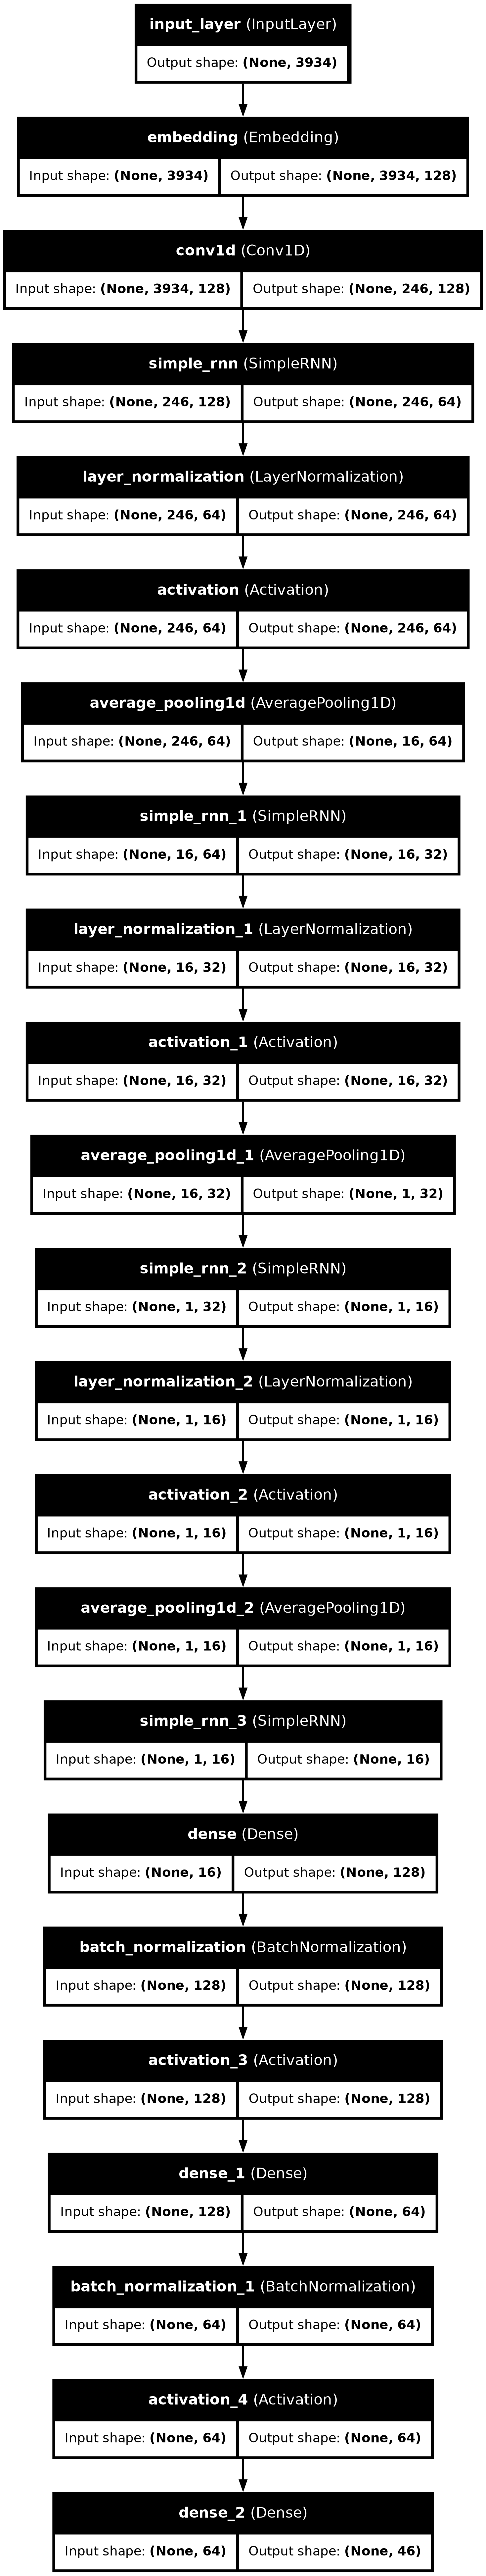

In [29]:
from IPython.display import Image

# Display the Image
Image("fig0a.png", width=400)

## Figure 0b) GRU Architecutre
The GRU Architecture had and embedding layer of 128, a convolution layer of 128, 3 GRU layers 64 -> 32 -> 16 with a sigmoid activation, & 2 dense layers of 128 -> 64 with a relu activation function. Learning rate was 10^{-3}. Dropout was 0.1.

(same as the SimpleRNN model except that the SimpleRNN layers are now GRU layers)

**Note**) The model took on average 6.5 hours to train (no gpu).

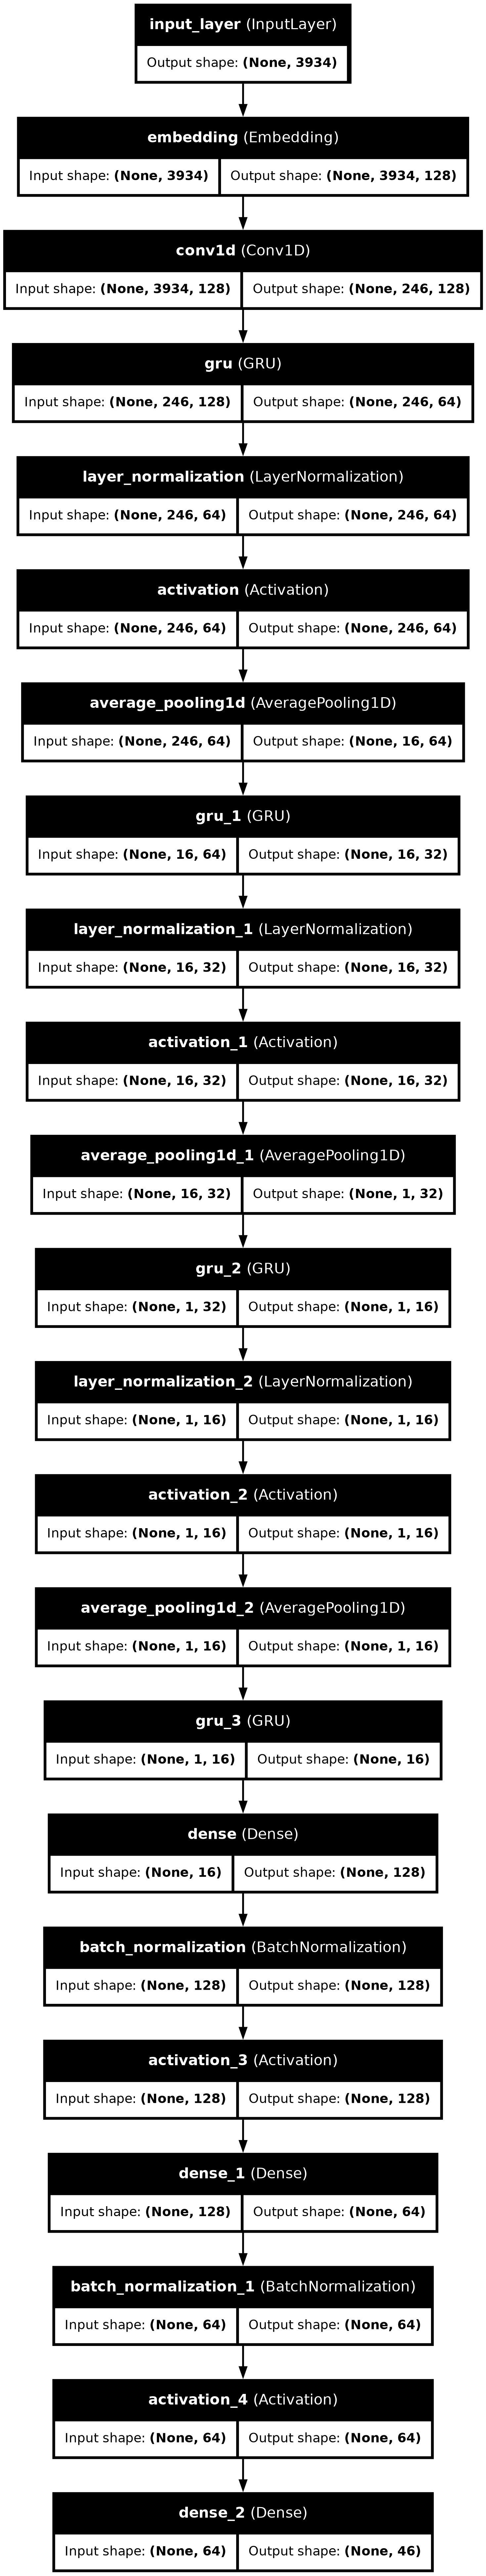

In [30]:
from IPython.display import Image

# Display the Image
Image("fig0b.png", width=400)

## Figure 0c) MHA Architecutre
The MHA (Multi-Headed Attention) Architecture had and embedding layer of 128, a rotation embedding layer of 128, a convolution layer of 128, 3 MHA layers 64 -> 32 -> 16 with a sigmoid activation, & 2 dense layers of 128 -> 64 with a relu activation function. Learning rate was 10^{-4}. Dropout was 0.1. THe number of attention heads was set to 8 (same as the attention paper).

**Note**) The model took on average 2 hours to train (gpu).

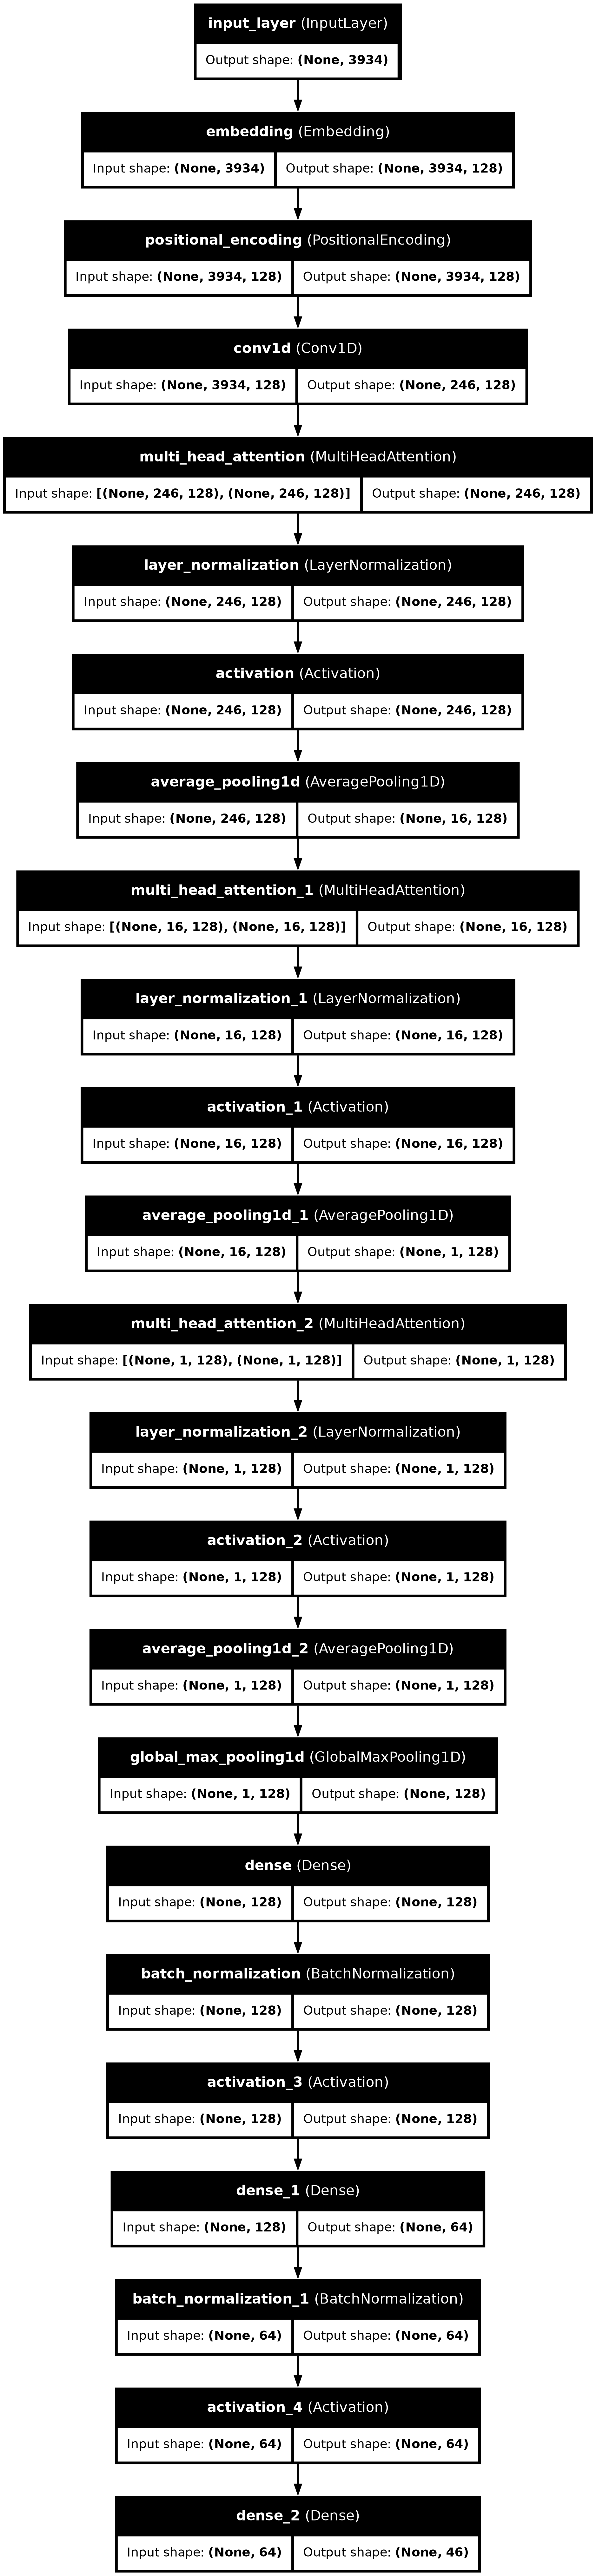

In [31]:
from IPython.display import Image

# Display the Image
Image("fig0c.png", width=400)

## Figure 1a)
In figure 1a we can see that all models get above 0.85 accuracy on the training set. We can also see that the SimpleRNN models on average just don't do as well as the MHA and the GRU models getting a lower training accuracy score on the later epochs. From this figure it also looks like the MHA has the overall performing training accuracy, but you can barely tell with the lines.

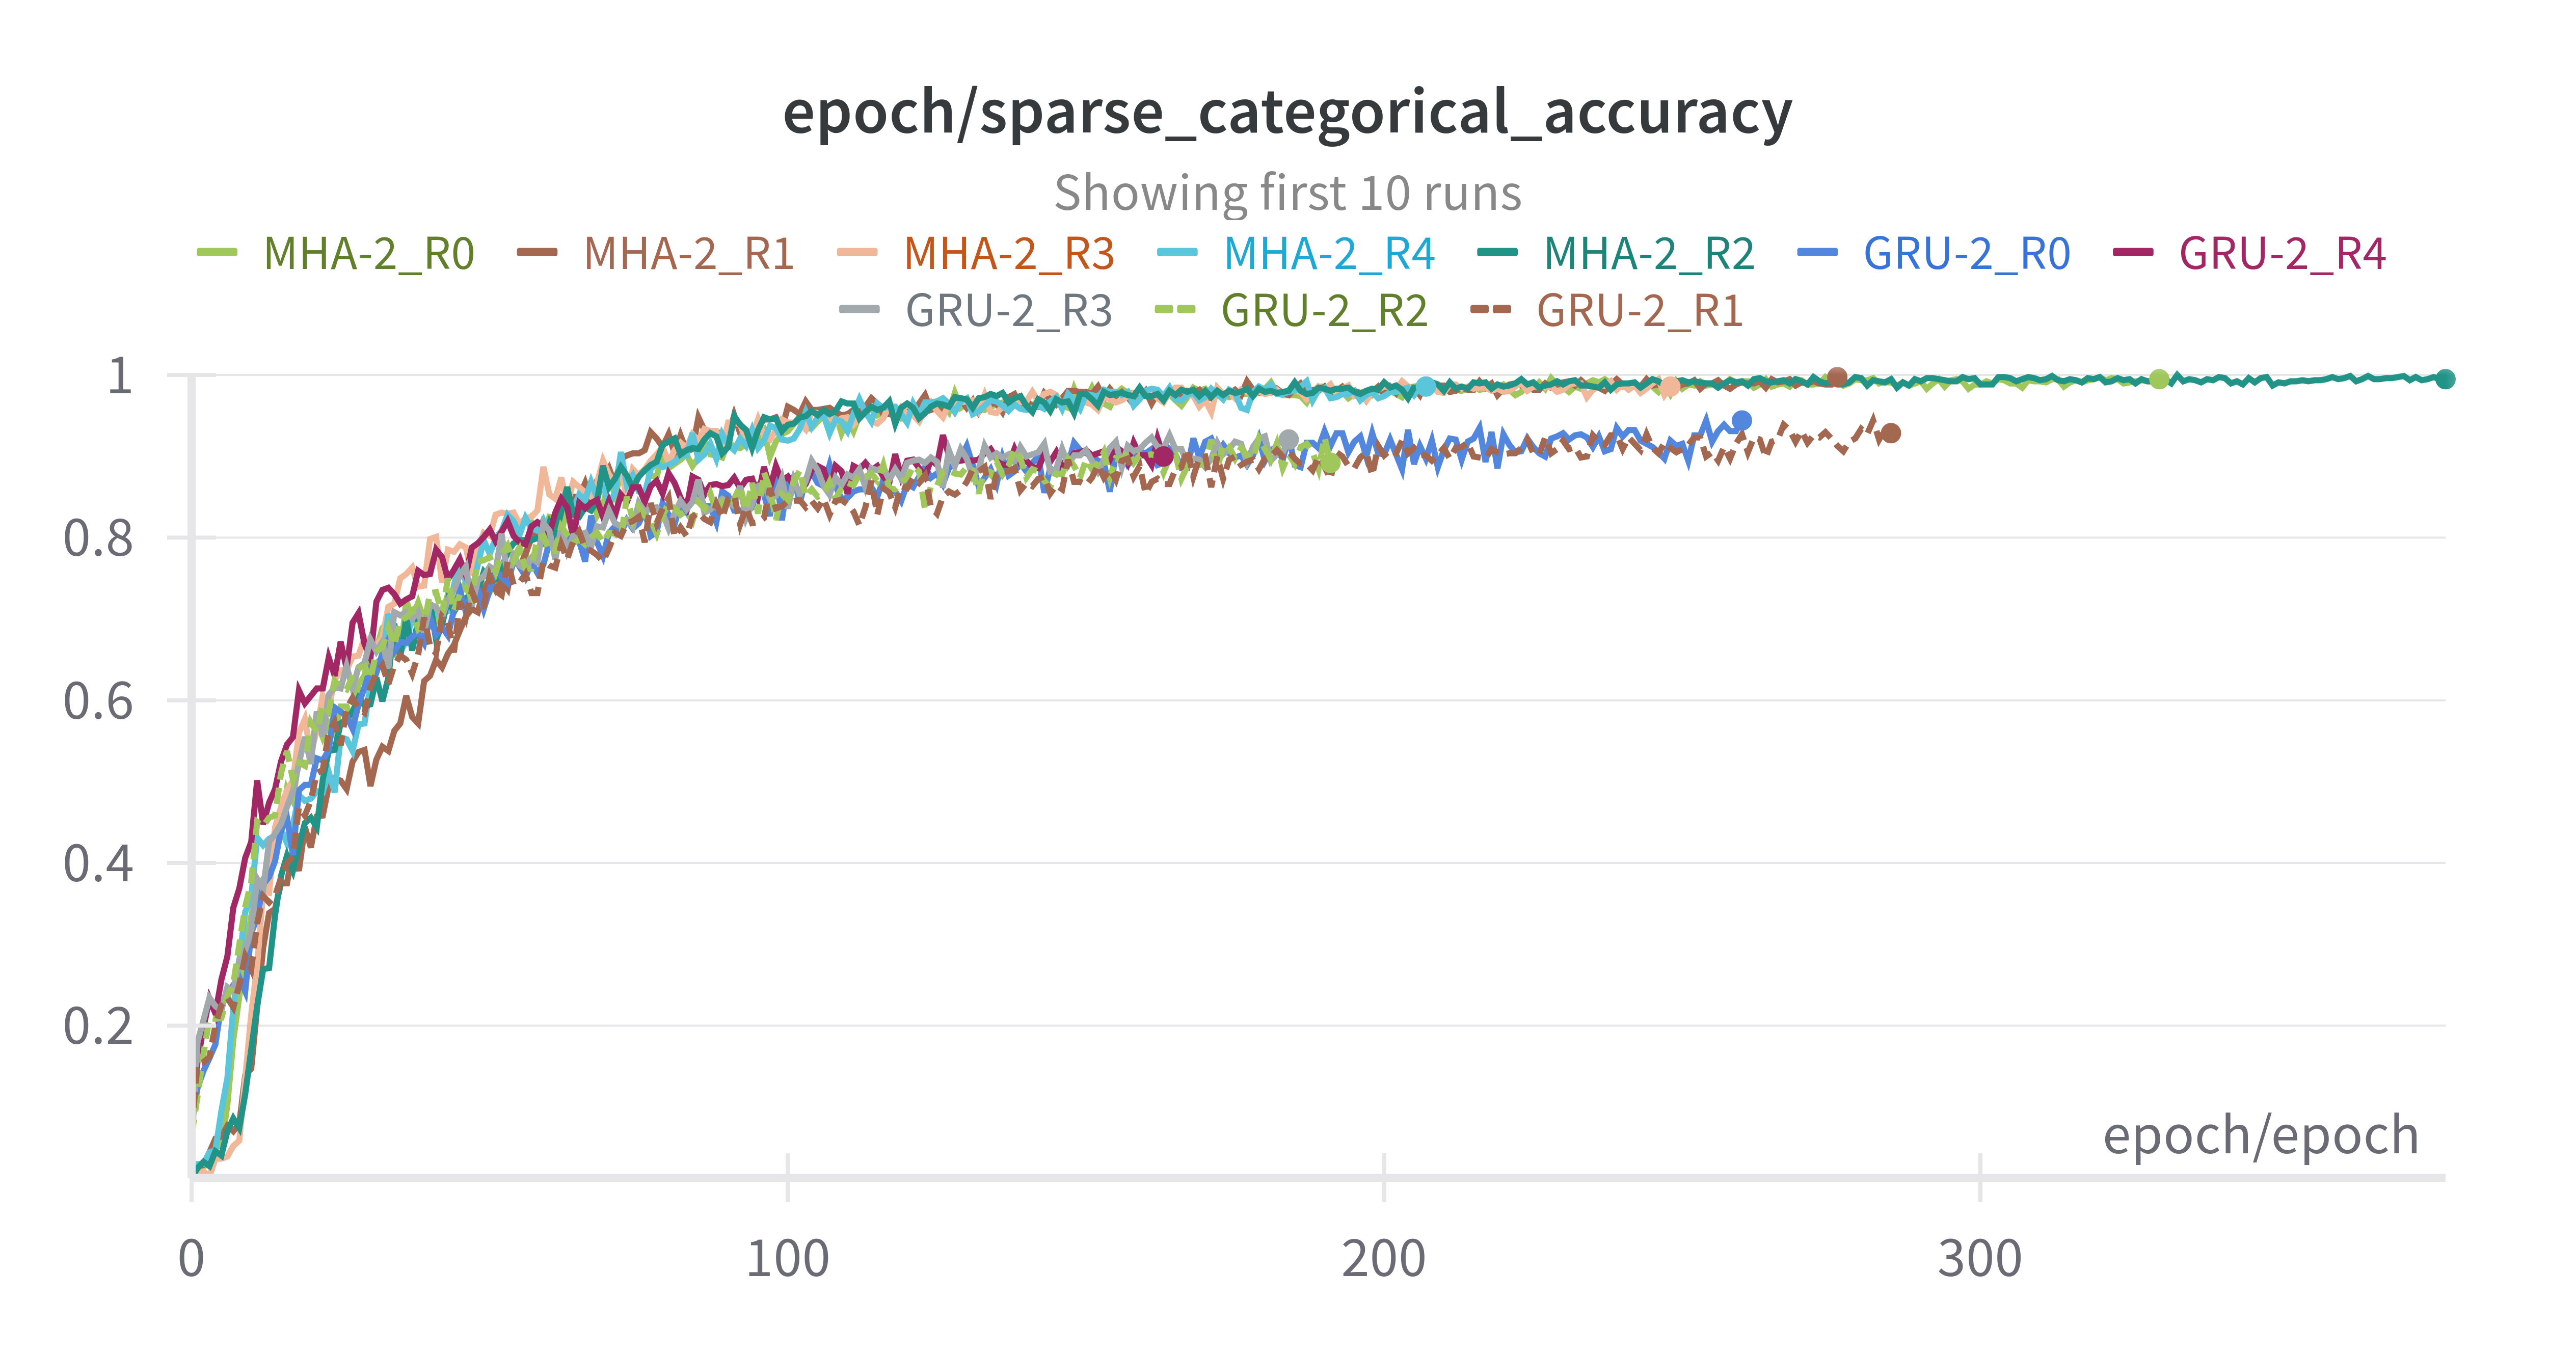

In [33]:
from IPython.display import Image

# Display the Image
Image("fig1a.png", width=800)

## Figure 1b)
In figure 1b we can see that all models get above 0.9 accuracy on the validation set. We can also see that the SimpleRNN models on average just don't do as well as the MHA and the GRU models getting a lower validation accuracy score on the later epochs. From this figure it also looks like the MHA has the overall performing validation accuracy, but you can barely tell with the lines.

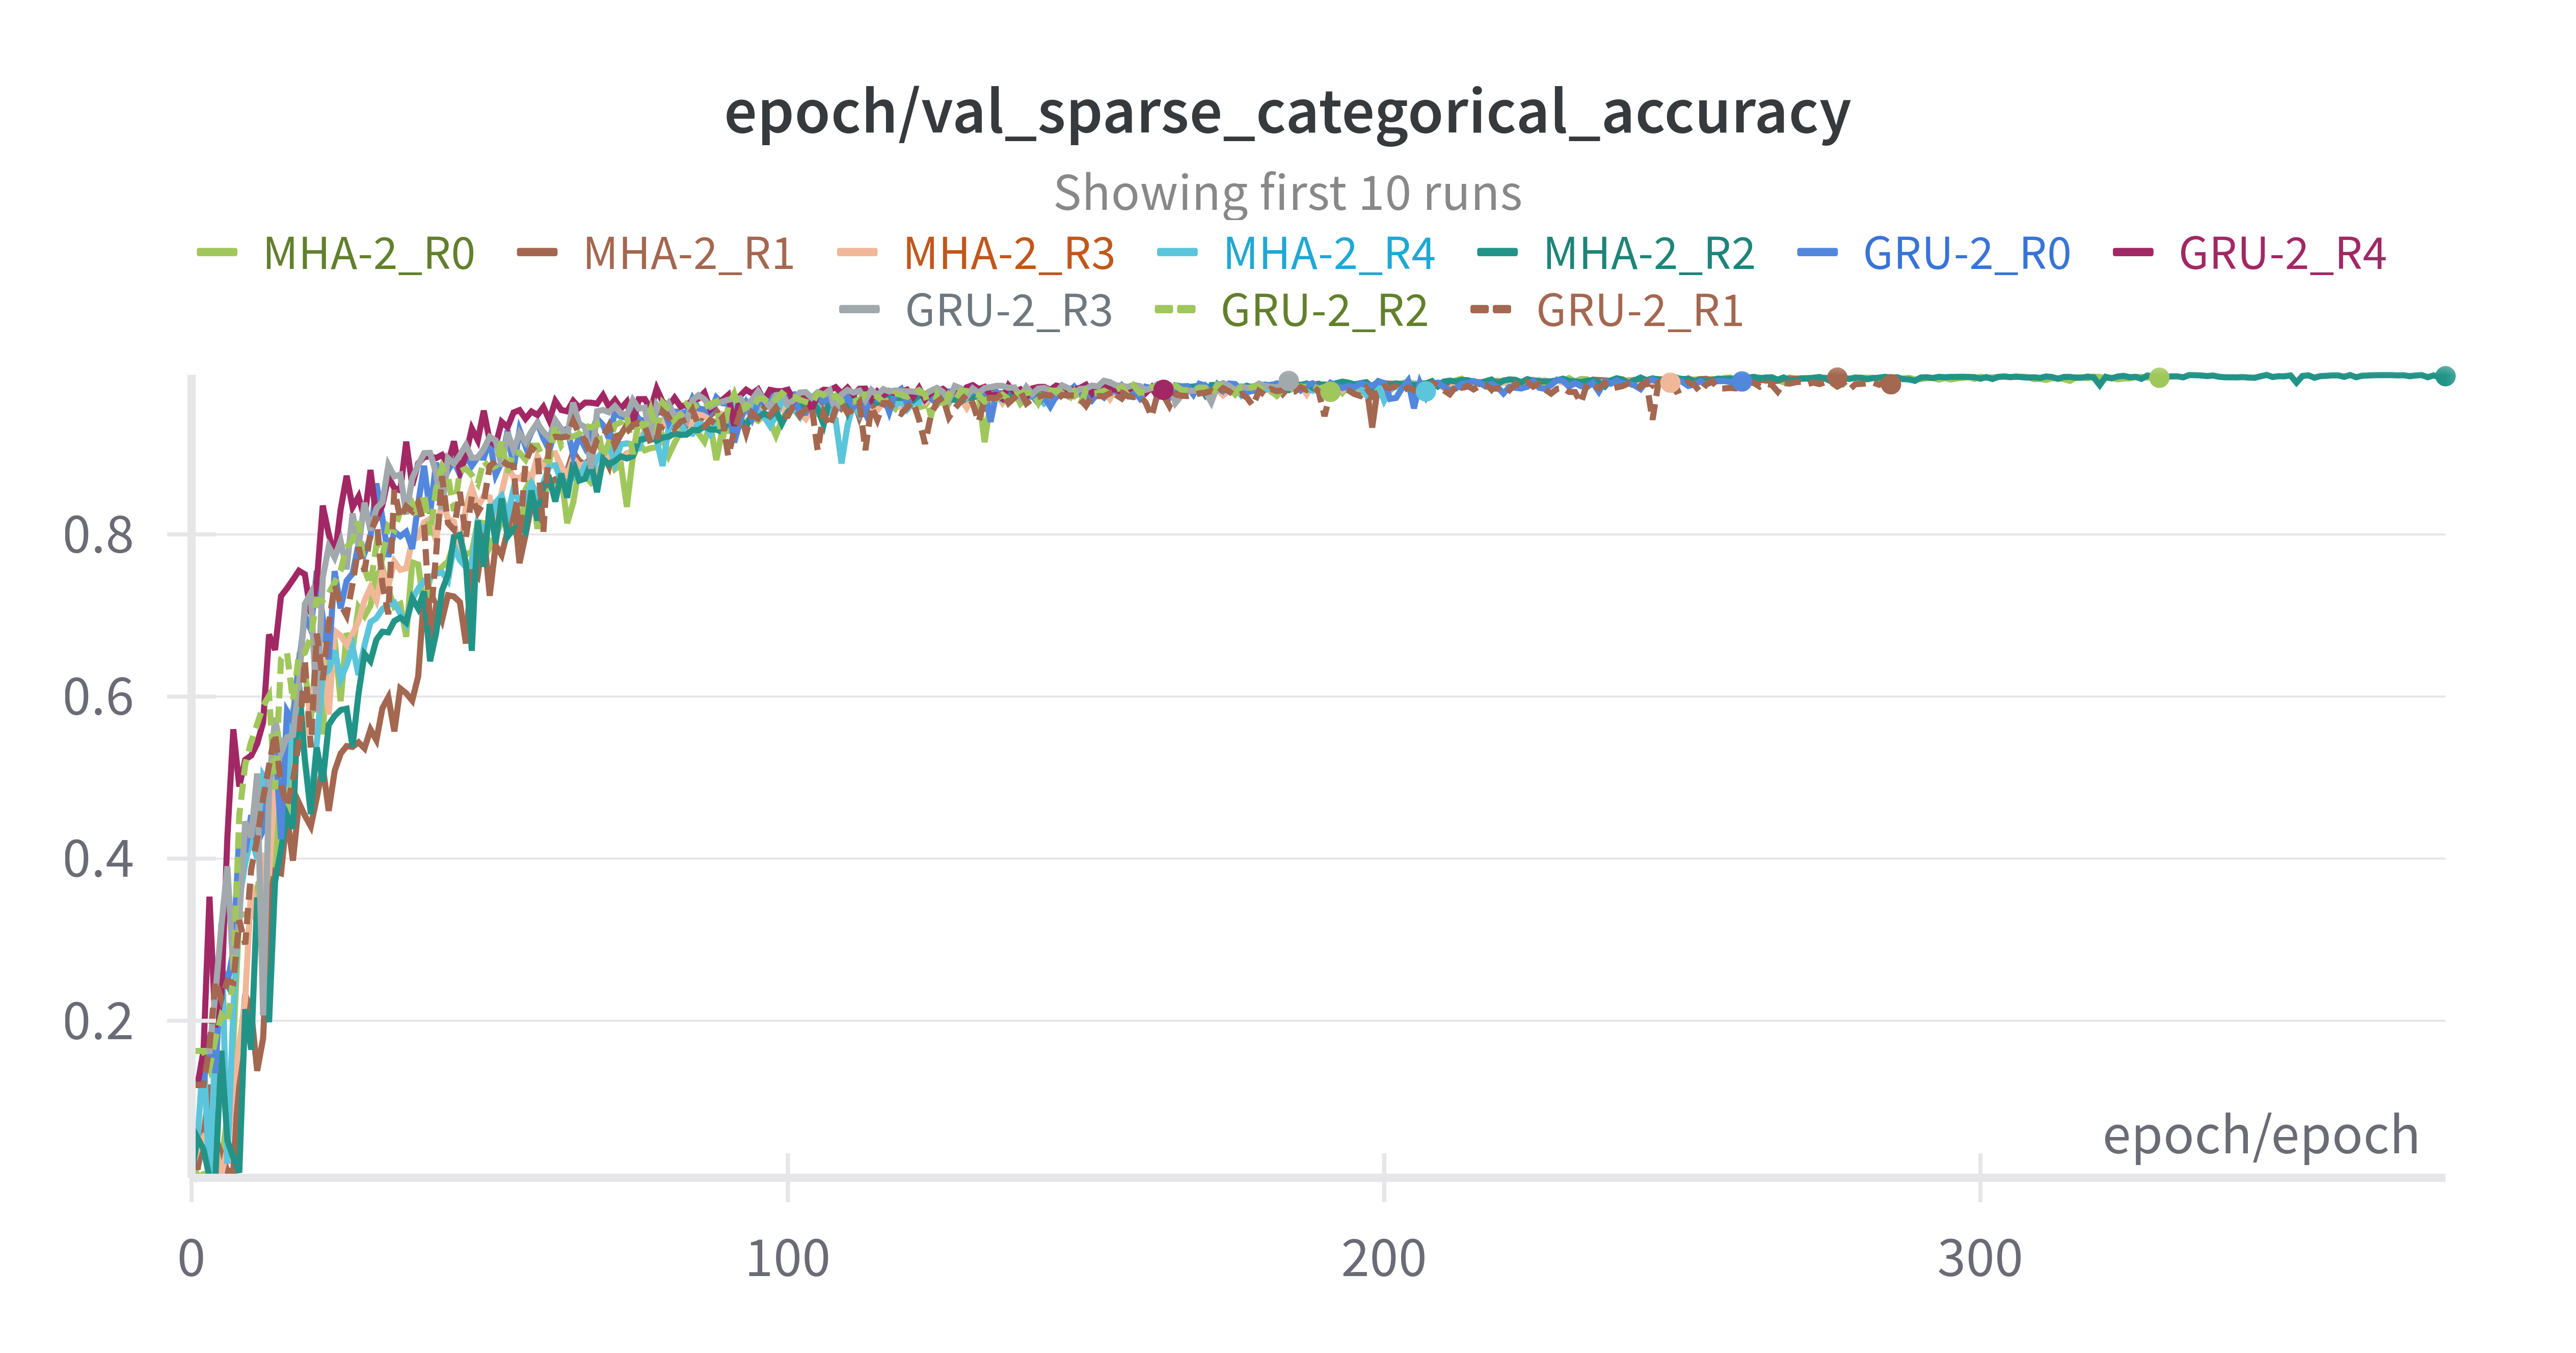

In [34]:
from IPython.display import Image

# Display the Image
Image("fig1b.png", width=800)

## Figure 2)
Here we compare the GRU training to the MHA training & see that GRU actually learns faster. Although this is not necessarily true in most cases because the learning rate of the MHA here is 10^{-4} vs 10^{-3} of the GRU model. However we do see that later on in the training, the upper right that all models end up in the left side of the image showing that MHA does perform better at the end, just takes longer epoch wise due to the lower learning rate (this was choosen b/c MHA is easily parallelizable vs GRU, although based of most online material, MHA per epoch learns faster than GRU usually).

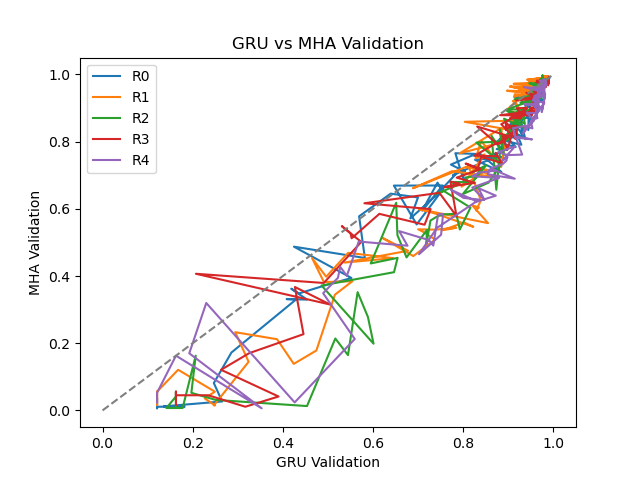

In [35]:
from IPython.display import Image

# Display the Image
Image("fig2.png", width=800)

## Figure 3)
Here we can see the test accuracy of all 3 models in each of there respective rotations and the immediate thing that comes to mind is that SimpleRNN rotation 4 performs poorly. We can assume this is from either initial weights and/or learning the wrong features to identify certain class categories. We can also see that MHA performs better on all 5 rotations, and GRU performs 2nd best on all but one rotation.



### Rotation Model Test Accuracies
=================================================

rnn rotation: 0 | rnn test acc: 0.9816882610321044

gru rotation: 0 | gru test acc: 0.9892926812171936

mha rotation: 0 | mha test acc: 0.9943792819976808

=================================================

rnn rotation: 1 | rnn test acc: 0.971567928791046

gru rotation: 1 | gru test acc: 0.9897095561027528

mha rotation: 1 | mha test acc: 0.9908783435821532

=================================================

rnn rotation: 2 | rnn test acc: 0.984953999519348

gru rotation: 2 | gru test acc: 0.9806079268455504

mha rotation: 2 | mha test acc: 0.9970517754554749

=================================================

rnn rotation: 3 | rnn test acc: 0.9721643328666688

gru rotation: 3 | gru test acc: 0.9879251718521118

mha rotation: 3 | mha test acc: 0.9877471923828124

=================================================

rnn rotation: 4 | rnn test acc: 0.6654630303382874

gru rotation: 4 | gru test acc: 0.9818440675735474

mha rotation: 4 | mha test acc: 0.983522355556488

=================================================

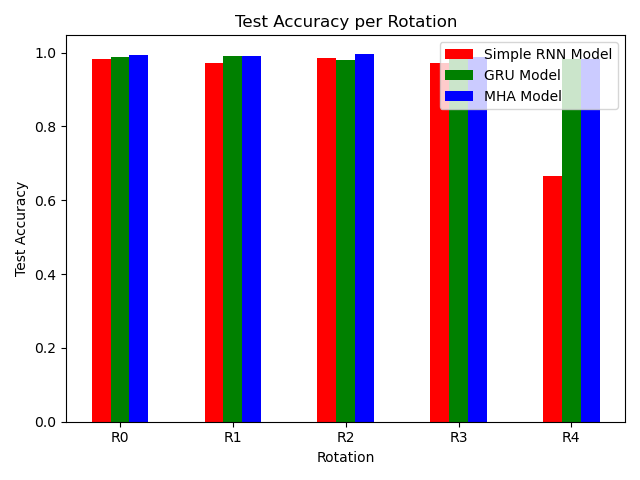

In [37]:
from IPython.display import Image

# Display the Image
Image("fig3.png", width=800)

## Figure 4)
This model is over the MHA models testset performance accross all 5 rotations (because MHA is the best performing model) and we can see that the model performs well and we know this due to the dark diagonal in the confusion matrix.

However it's interesting to note that the model misclassified all the members from class 44 and class 45, showing that the model didn't care to learn how to classify these classes due to them being relatively negligable to performance (because of their small size).

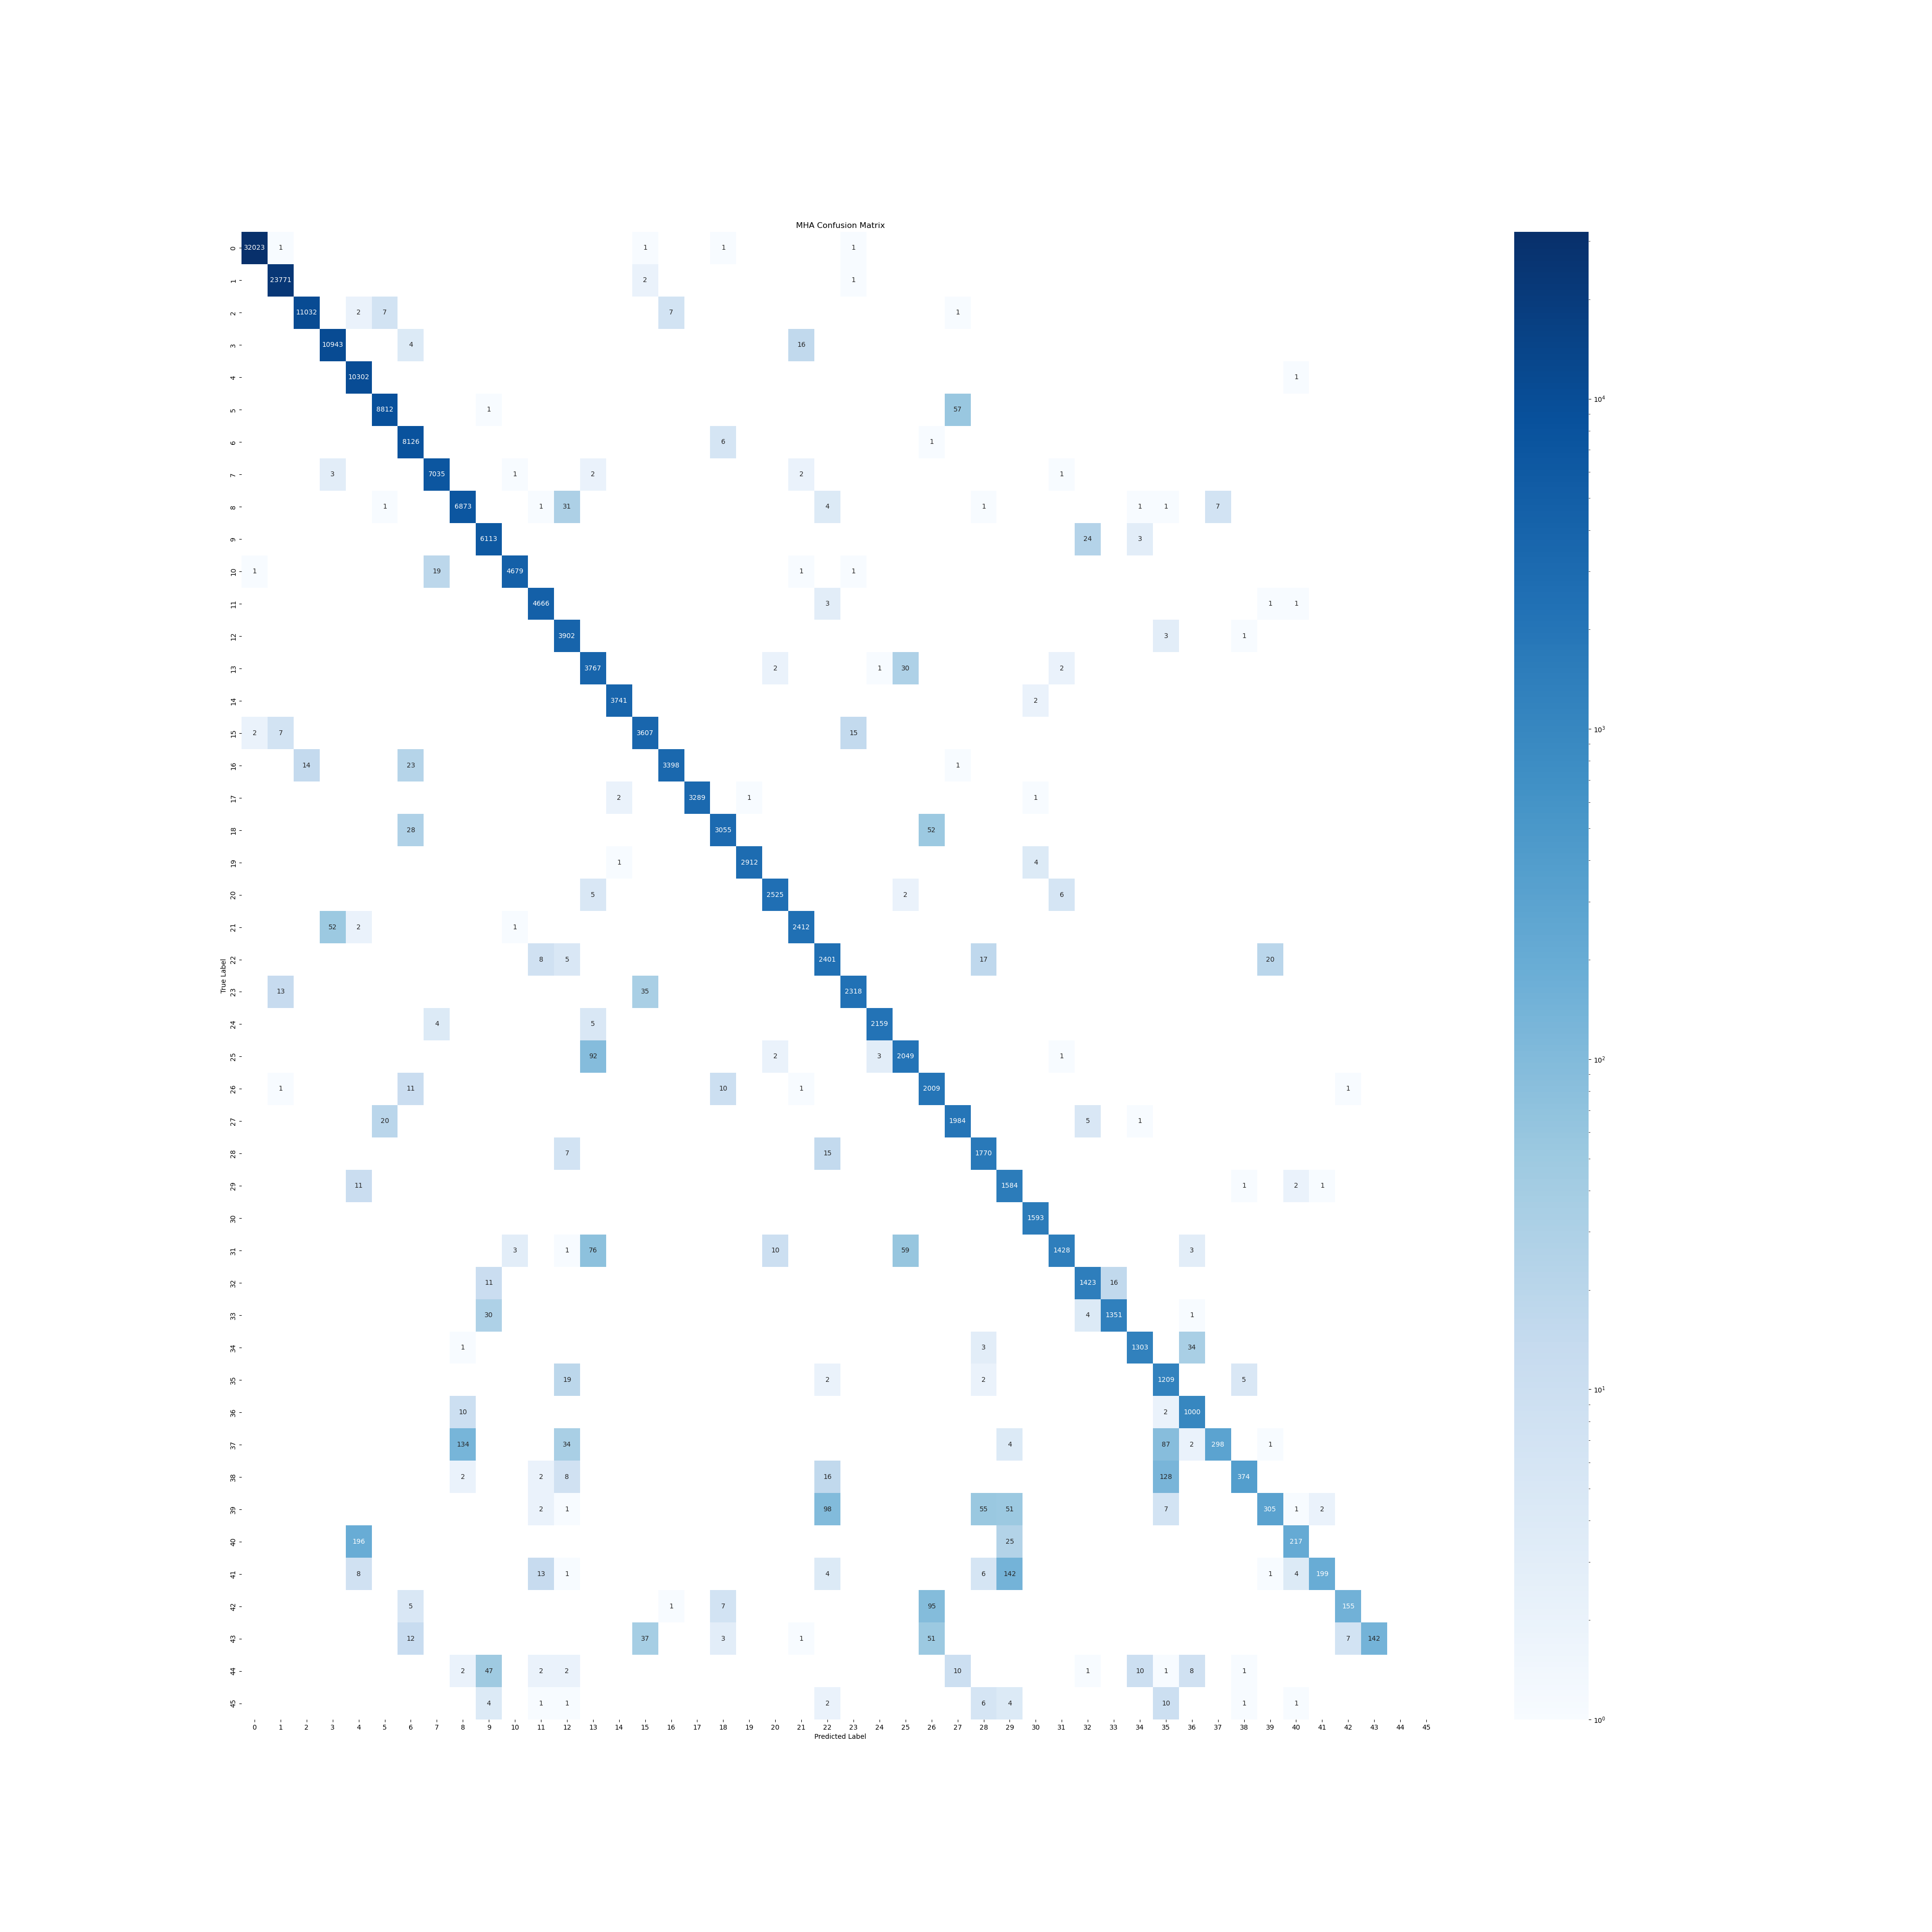

In [40]:
from IPython.display import Image

# Display the Image
Image("fig4.png", width=1500)


---

## Reflection

### 1) Describe the specific choices you made in the model architectures.
I tested a decent amount of arcitectures ranging from 5 layers to 2 layers, to a higher/lower embedding count, and even different convolutional striding amounts. However it seemed like the architecture I finally choose (similar for all 3 models) did the best for all three models.

I think the main thing to note was I tryed to have the final *special layer* (SimpleRNN, GRU, or MHA layer) be greater than 24 (because that was the tokan amount). Have the models be trainable in less than 12 hours (to train overnight) for relatively fast iteration from model to model. The MHA had a lower learning rate because of it's ability to use the GPU for faster learning in comparision to the other methods (didn't use unrolling).

### 2) Discuss in detail how consistent your model performance is across the different rotations.
The GRU and MHA models performed consistant across all 5 rotations, but the SimpleRNN model did very poorly on rotation 4, getting ~0.66 accuracy. This is probabily due to either poor weight initialization or just the model simply overfiting to rotation 4 because of the type of data in it. Outside of that one rotation though, the SimpleRNN test accuracy seemed to range from 0.97 to 0.985 (lowest overall performance regardless of outlier rotation). GRU seems to be the most consistent model having all of the rotations range inbetween 0.98 and 0.99 accuracy. MHA performs the best as one of it's rotations achieves 0.997 accuracy, however there are 2 rotations that are below that 0.99 accuracy range (still about 0.98 though).

### 3) Discuss the relative performance of the three model types.
This discussion of which model was better was already touched throughout this report but the model performance is in this order from wost to best (using accuracy as the main metric under consideration).

wosrt -> best

`SimpleRNN -> GRU -> MHA`

### 4) Compare and contrast the different models with respect to the required number of training epochs and the amount of time required to complete each epoch. Why does the third model type require so much compute time for each epoch?
With these architectures I tested the average epoch time for each of the models.

- **SimpleRNN** took around `30s` per epoch
- **GRU** took around `90s` per epoch
- **MHA** took around `180s` per epoch

However this MHA epoch time was without using the GPU in which that speed uptraining time to be even faster than the SimpleRNN.

The MHA (Multi-Headed Attention) model takes so much more time to compute in comparison with the other model types is because of the time it takes to compute all the matrix multiplication of the Q, K, V matricies. GRU doesn't have to worry about those 3 matricies and SimpleRNN definitely doesn't either.
